# Phần 3.2 — Phim nào bị chia sẻ lậu, khi nào, và vì sao

Dùng bảng đã tích hợp ở phần 3.1 (`torrents_clean`, `movie_analysis`): mỗi torrent đã được gắn với một phim IMDb, kèm thông tin TMDb (ngày ra rạp, ngày ra bản online/Digital theo từng nước). Mọi phân tích theo thời gian chỉ dùng **giai đoạn crawler ổn định 04/2021 – 09/2024** (phần 1.4).

**Thước đo:** *số torrent khác nhau* của mỗi phim = **nguồn cung** bản lậu (bao nhiêu bản được đăng), **không phải** số người tải (MagnetDB không có dữ liệu seeder/leecher). Không phân tích sâu bản quay lén CAM/TS vì nhãn ngắn, dễ nhận nhầm. Biểu đồ lưu vào `plots/7_piracy_movies/`.

In [1]:
# Tìm thư mục gốc dự án (chứa src/viz_style.py) để import phong cách biểu đồ dùng chung
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "viz_style.py").exists())
sys.path.insert(0, str(ROOT / "src"))
%matplotlib inline

## Nạp dữ liệu

In [2]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from matplotlib.ticker import FuncFormatter

import viz_style as V

V.setup()
FOLDER = "7_piracy_movies"
SRC = "Nguồn: MagnetDB, IMDb, TMDb; xử lý của nhóm."
P = lambda name: (V.DC / name).as_posix()
STABLE = ("2021-04-01", "2024-09-29")      # giai đoạn crawler ổn định (phần 1.4)
con = duckdb.connect()
con.execute(f"CREATE VIEW tor AS SELECT * FROM read_parquet('{P('torrents_clean.parquet')}') WHERE NOT implausible")
mv = duckdb.sql(f"SELECT * FROM read_parquet('{P('movie_analysis.parquet')}')").df()
print(f"{len(mv):,} phim có torrent; {mv['n_torrents_stable'].sum():,} lượt torrent trong giai đoạn ổn định")

126,081 phim có torrent; 923,998 lượt torrent trong giai đoạn ổn định


## 1. Phim nào bị chia sẻ lậu nhiều nhất?

  wrote plots\7_piracy_movies\01_top20_pirated.png


WindowsPath('D:/dulieulon/plots/7_piracy_movies/01_top20_pirated.png')

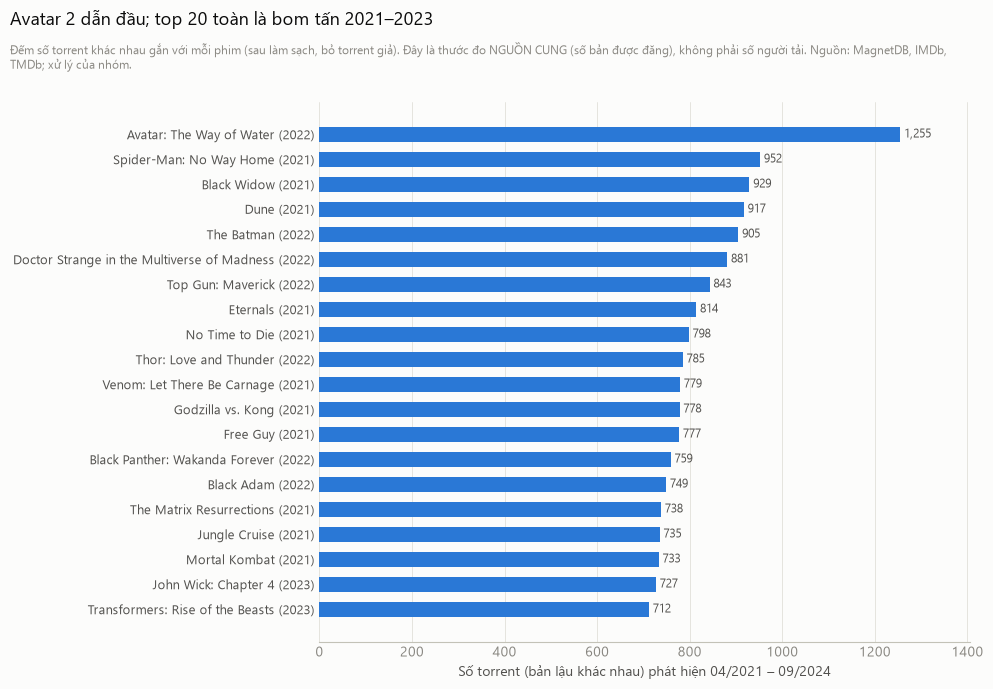

In [3]:
top = mv.nlargest(20, "n_torrents_stable")[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
V.style_axes(ax, grid="x")
y = np.arange(len(top))
ax.barh(y, top["n_torrents_stable"], color=V.BLUE, height=0.62)
for yi, v in zip(y, top["n_torrents_stable"]):
    ax.text(v + 8, yi, f"{v:,}", va="center", color=V.INK2, fontsize=8.5)
ax.set_yticks(y)
ax.set_yticklabels([f"{t} ({yr})" for t, yr in zip(top["title"], top["start_year"])], color=V.INK2, fontsize=9)
ax.set_xlim(0, top["n_torrents_stable"].max() * 1.12)
ax.set_xlabel("Số torrent (bản lậu khác nhau) phát hiện 04/2021 – 09/2024")
V.titles(fig, "Avatar 2 dẫn đầu; top 20 toàn là bom tấn 2021–2023",
         f"Đếm số torrent khác nhau gắn với mỗi phim (sau làm sạch, bỏ torrent giả). Đây là thước đo NGUỒN CUNG "
         f"(số bản được đăng), không phải số người tải. {SRC}")
V.save(fig, FOLDER, "01_top20_pirated")

**Nhận xét.** Top 20 toàn là **bom tấn Hollywood 2021–2023**: *Avatar: The Way of Water* dẫn đầu (~1.250 bản), rồi *Spider-Man: No Way Home*, *Black Widow*, *Dune*, *The Batman*. Nhiều phim trong top (Black Widow, Dune, Matrix Resurrections, Mortal Kombat, Godzilla vs. Kong) từng **phát hành online cùng ngày ra rạp** năm 2021 (HBO Max, Disney+ Premier Access).

## 2. Phim nổi tiếng hơn có bị lậu nhiều hơn không?

  wrote plots\7_piracy_movies\02_popularity_vs_piracy.png


WindowsPath('D:/dulieulon/plots/7_piracy_movies/02_popularity_vs_piracy.png')

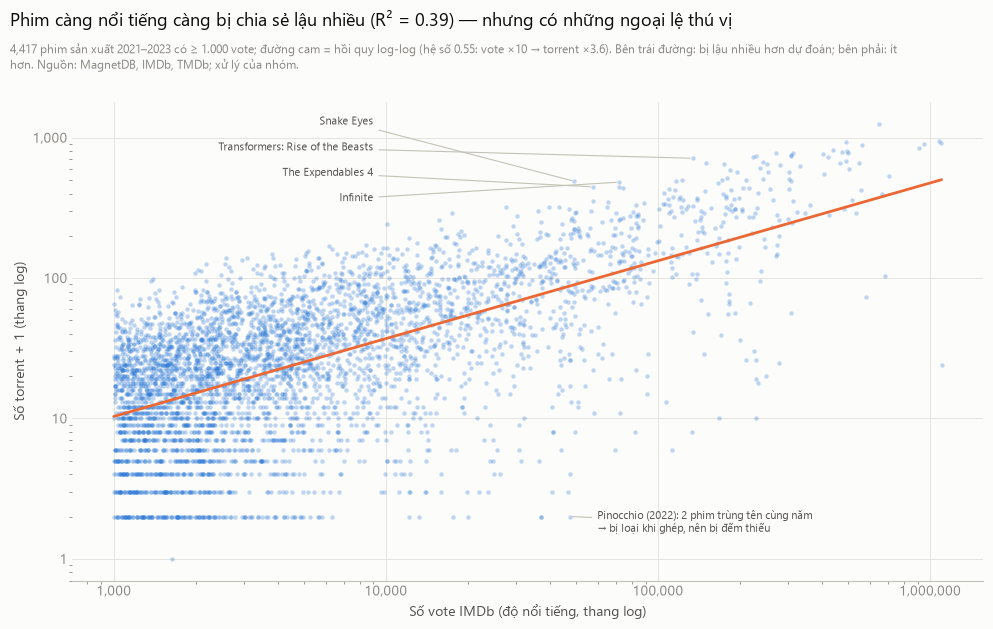

In [4]:
d = mv[mv["start_year"].between(2021, 2023) & (mv["num_votes"] >= 1000)].copy()
d["lv"], d["lt"] = np.log10(d["num_votes"]), np.log10(d["n_torrents_stable"] + 1)
b, a = np.polyfit(d["lv"], d["lt"], 1)
d["resid"] = d["lt"] - (a + b * d["lv"])
fig, ax = plt.subplots(figsize=(10, 6.4))
V.style_axes(ax, grid="both")
ax.scatter(d["num_votes"], d["n_torrents_stable"] + 1, s=10, color=V.BLUE, alpha=0.3, linewidths=0)
xs = np.linspace(d["lv"].min(), d["lv"].max(), 50)
ax.plot(10 ** xs, 10 ** (a + b * xs), color=V.ORANGE)
r2 = np.corrcoef(d["lv"], d["lt"])[0, 1] ** 2
pop = d[d["num_votes"] >= 30000]
# Phim bị lậu nhiều hơn dự đoán: ghi tên so le phía trên-trái
for (_, r), ty in zip(pop.nlargest(4, "resid").iterrows(), (1300, 850, 560, 370)):
    ax.annotate(r["title"], xy=(r["num_votes"], r["n_torrents_stable"] + 1), xytext=(9000, ty),
                textcoords="data", ha="right", va="center", color=V.INK2, fontsize=8,
                arrowprops=dict(arrowstyle="-", color=V.AXIS, linewidth=0.8))
# Phía dưới đường: phần lớn là LỖI ĐO (tên trùng bị loại khi ghép), không phải phim "ít bị lậu"
pin = d[d["title"].eq("Pinocchio") & d["start_year"].eq(2022)]
if len(pin):
    r = pin.iloc[0]
    ax.annotate("Pinocchio (2022): 2 phim trùng tên cùng năm\n→ bị loại khi ghép, nên bị đếm thiếu",
                xy=(r["num_votes"], r["n_torrents_stable"] + 1), xytext=(20, -4), textcoords="offset points",
                va="center", color=V.INK2, fontsize=8, arrowprops=dict(arrowstyle="-", color=V.AXIS, linewidth=0.8))
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(V.fmt_int))
ax.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
ax.set_xlabel("Số vote IMDb (độ nổi tiếng, thang log)")
ax.set_ylabel("Số torrent + 1 (thang log)")
V.titles(fig, f"Phim càng nổi tiếng càng bị chia sẻ lậu nhiều (R² = {r2:.2f}) — nhưng có những ngoại lệ thú vị",
         f"{len(d):,} phim sản xuất 2021–2023 có ≥ 1.000 vote; đường cam = hồi quy log-log (hệ số {b:.2f}: vote ×10 → torrent ×{10 ** b:.1f}). "
         f"Bên trái đường: bị lậu nhiều hơn dự đoán; bên phải: ít hơn. {SRC}")
V.save(fig, FOLDER, "02_popularity_vs_piracy")

**Nhận xét.** Có: quan hệ log-log khá chặt (**R² ≈ 0,39**), số vote ×10 thì số torrent ×~3,6. Phim nằm **xa phía trên đường** bị chia sẻ lậu nhiều hơn mức nổi tiếng — chủ yếu phim hành động thương mại (*Transformers: Rise of the Beasts, Snake Eyes, The Expendables 4, Infinite*). Các điểm **xa phía dưới** cần thận trọng: nhiều ca là **lỗi đo** — vd. *Pinocchio (2022)* có hai phim trùng tên cùng năm nên bị loại khi ghép.

## 3. Thể loại nào bị lậu nhiều hơn mức nổi tiếng của nó?

  wrote plots\7_piracy_movies\03_genre_piracy_ratio.png


WindowsPath('D:/dulieulon/plots/7_piracy_movies/03_genre_piracy_ratio.png')

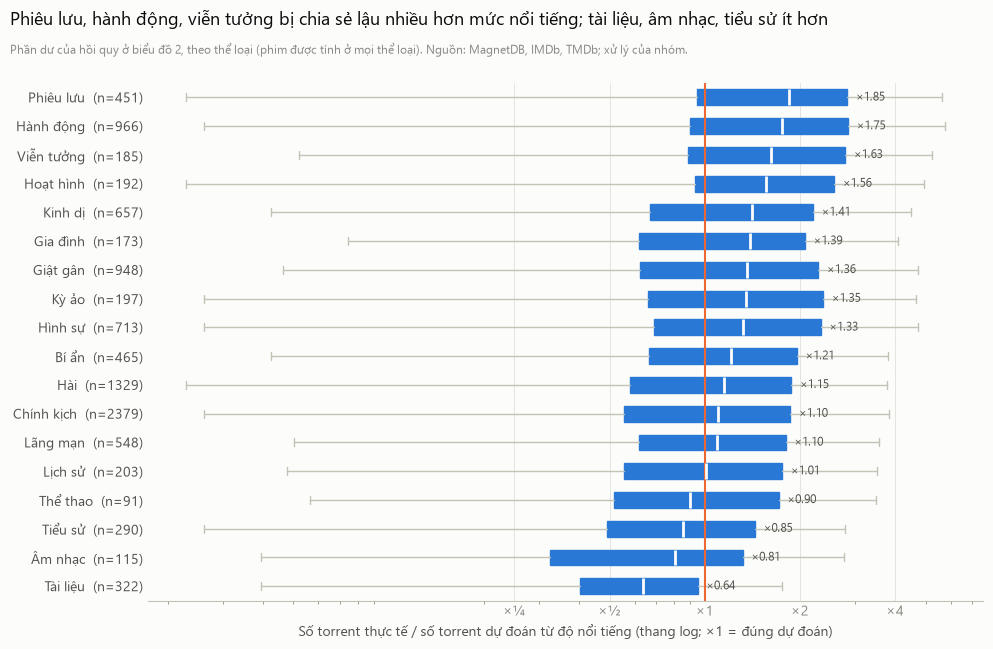

In [5]:
g = d.assign(genre=d["genres"].str.split(",")).explode("genre")
cnt = g["genre"].value_counts()
g = g[g["genre"].isin(cnt[cnt >= 60].index) & (g["genre"] != "Adult")]
order = g.groupby("genre")["resid"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 6.6))
V.style_axes(ax, grid="x")
data = [10 ** g.loc[g["genre"] == x, "resid"].values for x in order]
ax.boxplot(data, orientation="horizontal", widths=0.55, patch_artist=True, showfliers=False,
           medianprops=dict(color=V.SURFACE, linewidth=2), whiskerprops=dict(color=V.AXIS),
           capprops=dict(color=V.AXIS), boxprops=dict(facecolor=V.BLUE, edgecolor=V.BLUE))
ax.axvline(1, color=V.ORANGE, linewidth=1.5)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4])
ax.set_xticklabels(["×¼", "×½", "×1", "×2", "×4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{V.GENRE_VI.get(x, x)}  (n={cnt[x]})" for x in order], color=V.INK2)
for i, x in enumerate(order, 1):
    m = np.median(data[i - 1])
    ax.annotate(f"×{m:.2f}", xy=(np.percentile(data[i - 1], 75), i), xytext=(6, 0),
                textcoords="offset points", va="center", color=V.INK2, fontsize=8.5)
ax.set_xlabel("Số torrent thực tế / số torrent dự đoán từ độ nổi tiếng (thang log; ×1 = đúng dự đoán)")
V.titles(fig, "Phiêu lưu, hành động, viễn tưởng bị chia sẻ lậu nhiều hơn mức nổi tiếng; tài liệu, âm nhạc, tiểu sử ít hơn",
         f"Phần dư của hồi quy ở biểu đồ 2, theo thể loại (phim được tính ở mọi thể loại). {SRC}")
V.save(fig, FOLDER, "03_genre_piracy_ratio")

**Nhận xét.** Sau khi trừ đi ảnh hưởng của độ nổi tiếng, **phiêu lưu (×1,85), hành động (×1,75), viễn tưởng, hoạt hình** bị chia sẻ lậu nhiều hơn dự đoán; **tài liệu (×0,64), âm nhạc, tiểu sử** ít hơn. Phim "xem vì hiệu ứng hình ảnh" là loại được săn bản lậu chất lượng cao nhiều nhất.

## 4. Phim nói tiếng gì bị lậu nhiều so với độ nổi tiếng?

  wrote plots\7_piracy_movies\04_language_piracy_ratio.png


WindowsPath('D:/dulieulon/plots/7_piracy_movies/04_language_piracy_ratio.png')

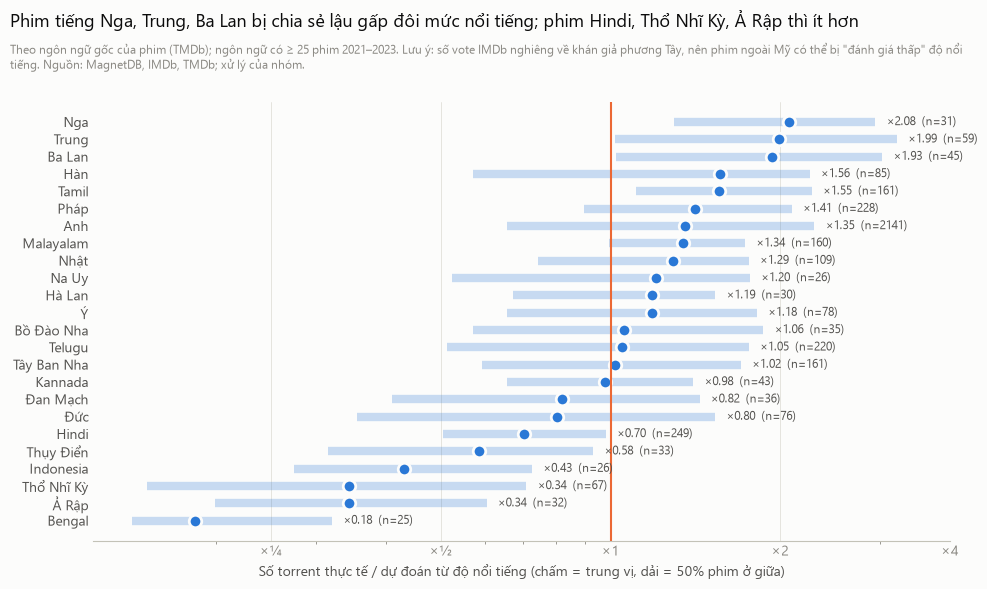

In [6]:
LANG = {"en": "Anh", "hi": "Hindi", "te": "Telugu", "ta": "Tamil", "ml": "Malayalam", "ko": "Hàn", "ja": "Nhật",
        "fr": "Pháp", "es": "Tây Ban Nha", "it": "Ý", "de": "Đức", "zh": "Trung", "ru": "Nga", "tr": "Thổ Nhĩ Kỳ",
        "pt": "Bồ Đào Nha", "pl": "Ba Lan", "kn": "Kannada", "th": "Thái", "id": "Indonesia",
        "no": "Na Uy", "nl": "Hà Lan", "da": "Đan Mạch", "sv": "Thụy Điển", "ar": "Ả Rập", "bn": "Bengal",
        "fi": "Phần Lan", "cn": "Quảng Đông", "uk": "Ukraina", "tl": "Tagalog", "fa": "Ba Tư"}
lg = d.groupby("original_language")["resid"].agg(["median", "count",
                                                   lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])
lg.columns = ["median", "n", "q1", "q3"]
lg = lg[lg["n"] >= 25].sort_values("median")
fig, ax = plt.subplots(figsize=(10, 6))
V.style_axes(ax, grid="x")
y = np.arange(len(lg))
ax.hlines(y, 10 ** lg["q1"], 10 ** lg["q3"], color=V.BLUE, linewidth=6, alpha=0.25)
ax.plot(10 ** lg["median"], y, "o", markersize=9, color=V.BLUE, markeredgecolor=V.SURFACE, markeredgewidth=2)
ax.axvline(1, color=V.ORANGE, linewidth=1.5)
for yi, (code, r) in zip(y, lg.iterrows()):
    ax.annotate(f"×{10 ** r['median']:.2f}  (n={int(r['n'])})", xy=(10 ** r["q3"], yi), xytext=(8, 0),
                textcoords="offset points", va="center", color=V.INK2, fontsize=8.5)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4])
ax.set_xticklabels(["×¼", "×½", "×1", "×2", "×4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y)
ax.set_yticklabels([LANG.get(c, c) for c in lg.index], color=V.INK2)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Số torrent thực tế / dự đoán từ độ nổi tiếng (chấm = trung vị, dải = 50% phim ở giữa)")
V.titles(fig, "Phim tiếng Nga, Trung, Ba Lan bị chia sẻ lậu gấp đôi mức nổi tiếng; phim Hindi, Thổ Nhĩ Kỳ, Ả Rập thì ít hơn",
         f"Theo ngôn ngữ gốc của phim (TMDb); ngôn ngữ có ≥ 25 phim 2021–2023. Lưu ý: số vote IMDb nghiêng về khán giả phương Tây, "
         f"nên phim ngoài Mỹ có thể bị \"đánh giá thấp\" độ nổi tiếng. {SRC}")
V.save(fig, FOLDER, "04_language_piracy_ratio")

**Nhận xét.** Phim tiếng **Nga (×2,1), Trung (×2,0), Ba Lan (×1,9)** bị chia sẻ gấp đôi mức nổi tiếng — khớp với phần 1.4: cộng đồng Kirin và Hán rất đông trên DHT, Ba Lan có văn hóa lồng tiếng (*lektor*) riêng. Ngược lại phim **Hindi, Thổ Nhĩ Kỳ, Ả Rập, Bengal** ít hơn nhiều: khán giả các nước này có thể xem lậu qua kênh khác (web xem trực tuyến, Telegram) mà MagnetDB không ghi nhận. Lưu ý: số vote IMDb nghiêng về khán giả phương Tây.

## 5. Bản lậu mới thuộc phim mới hay phim cũ?

  wrote plots\7_piracy_movies\05_film_age_of_uploads.png


WindowsPath('D:/dulieulon/plots/7_piracy_movies/05_film_age_of_uploads.png')

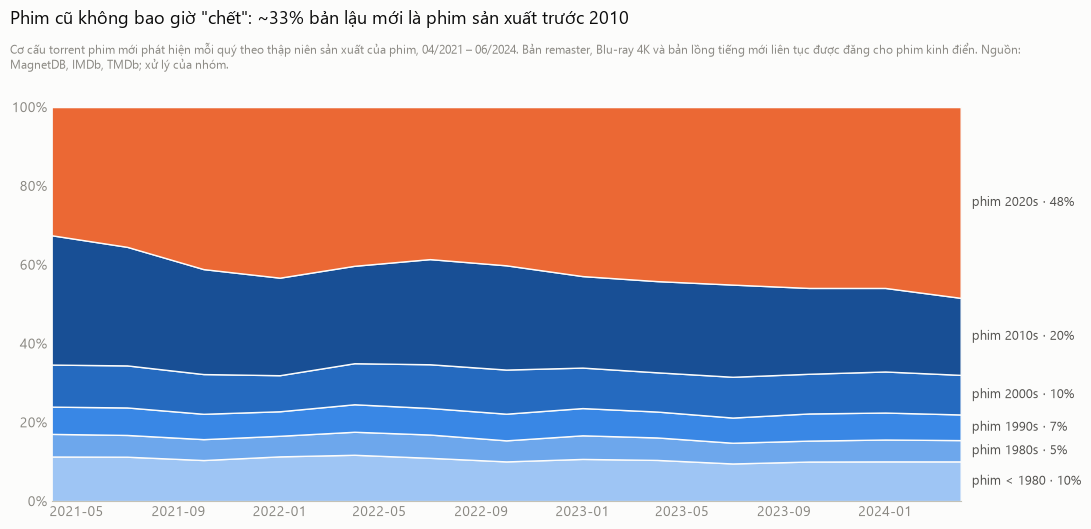

In [7]:
age = con.execute(f"""
    SELECT date_trunc('quarter', t.discovered_at_utc) AS q,
           CASE WHEN m.start_year < 1980 THEN '< 1980' WHEN m.start_year < 1990 THEN '1980s'
                WHEN m.start_year < 2000 THEN '1990s' WHEN m.start_year < 2010 THEN '2000s'
                WHEN m.start_year < 2020 THEN '2010s' ELSE '2020s' END AS dec,
           count(*) AS n
    FROM tor t JOIN read_parquet('{P('movie_analysis.parquet')}') m USING (imdb_id)
    WHERE t.discovered_at_utc BETWEEN '{STABLE[0]}' AND '2024-06-30'
    GROUP BY 1, 2
""").df().pivot(index="q", columns="dec", values="n").fillna(0)
DEC = ["< 1980", "1980s", "1990s", "2000s", "2010s", "2020s"]
share = age[DEC].div(age.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 5.4))
V.style_axes(ax, grid=None)
cols = [V.SEQ_STEPS[1], V.SEQ_STEPS[2], V.SEQ_STEPS[3], V.SEQ_STEPS[4], V.SEQ_STEPS[5], V.ORANGE]
ax.stackplot(share.index, share.T.values, colors=cols, edgecolor=V.SURFACE, linewidth=1)
cum = share.iloc[-1].cumsum()
for dec, top_v, v in zip(DEC, cum, share.iloc[-1]):
    ax.annotate(f"phim {dec} · {v:.0%}", xy=(share.index[-1], top_v - v / 2), xytext=(8, 0),
                textcoords="offset points", va="center", color=V.INK2, fontsize=9)
ax.set_ylim(0, 1)
ax.set_xlim(share.index[0], share.index[-1])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.subplots_adjust(right=0.8)
old = share[["< 1980", "1980s", "1990s", "2000s"]].sum(axis=1).mean()
V.titles(fig, f"Phim cũ không bao giờ \"chết\": ~{old:.0%} bản lậu mới là phim sản xuất trước 2010",
         f"Cơ cấu torrent phim mới phát hiện mỗi quý theo thập niên sản xuất của phim, 04/2021 – 06/2024. "
         f"Bản remaster, Blu-ray 4K và bản lồng tiếng mới liên tục được đăng cho phim kinh điển. {SRC}")
V.save(fig, FOLDER, "05_film_age_of_uploads")

**Nhận xét.** Chỉ khoảng **40–48%** bản lậu mới là phim của thập niên 2020; **~1/3 là phim sản xuất trước 2010**, ~10% là phim trước 1980. Phim kinh điển liên tục được đăng lại dưới dạng remaster, Blu-ray 4K, bản lồng tiếng mới — **phim cũ không bao giờ "chết"** trên mạng chia sẻ.

## 6. Điều gì xảy ra khi phim ra bản xem hợp pháp online?

  wrote plots\7_piracy_movies\06_event_study_digital.png
  wrote plots\7_piracy_movies\07_web_lag.png


     grp  ratio    lo    hi     p   n
same_day   1.14 0.983 1.321 0.083 403
  w04_45   1.00   NaN   NaN   NaN 385
  w46_90   0.94 0.776 1.138 0.525 141
 w90plus   0.71 0.520 0.970 0.031  60
  wrote plots\7_piracy_movies\08_release_strategy_effect.png


WindowsPath('D:/dulieulon/plots/7_piracy_movies/08_release_strategy_effect.png')

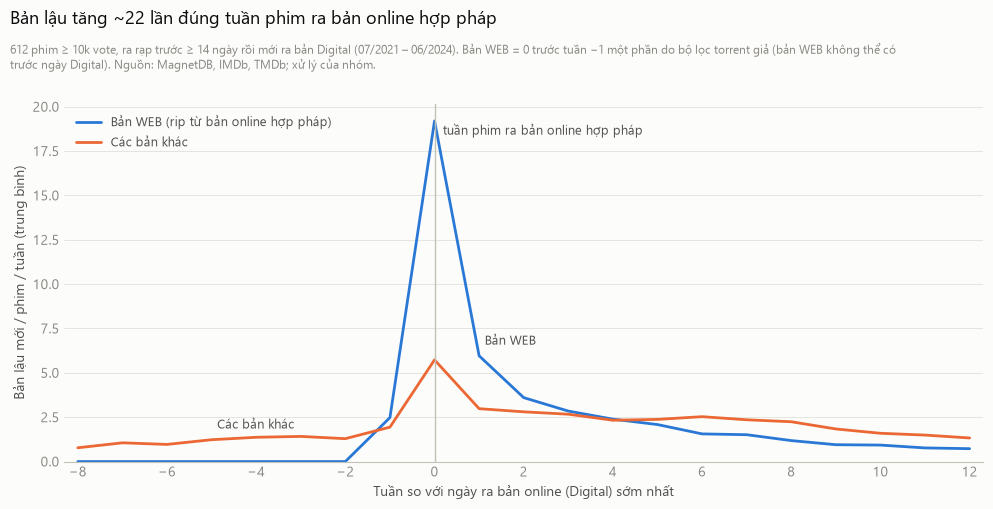

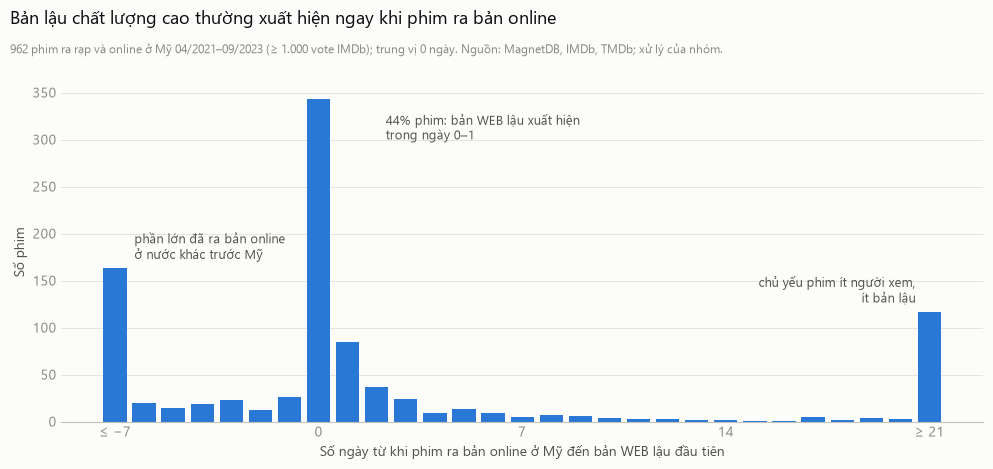

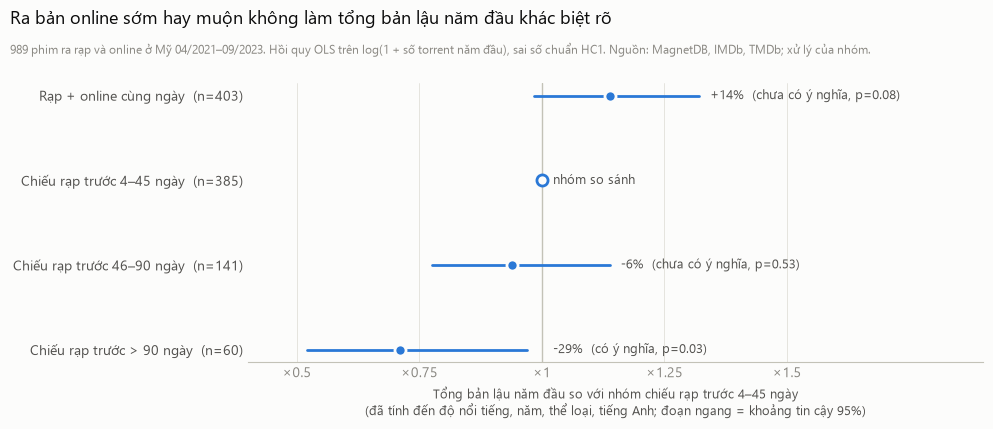

In [8]:
WEEKS = (-8, 12)
con.register("mv_df", mv)
con.execute("""CREATE TEMP VIEW es AS SELECT * FROM mv_df
               WHERE first_digital BETWEEN '2021-07-01' AND '2024-06-30'
                 AND digital_days_after_theatrical >= 14 AND num_votes >= 10000""")
n_es = con.execute("SELECT count(*) FROM es").fetchone()[0]
weekly = con.execute(f"""
    WITH w AS (SELECT t.quality_tier,
                      floor(date_diff('day', s.first_digital, t.discovered_at_utc::DATE) / 7)::INT AS week
               FROM tor t JOIN es s USING (imdb_id) WHERE t.in_stable_window)
    SELECT week, count(*) FILTER (WHERE quality_tier = 'web') / {n_es} AS web,
                 count(*) FILTER (WHERE quality_tier <> 'web') / {n_es} AS other
    FROM w WHERE week BETWEEN {WEEKS[0]} AND {WEEKS[1]} GROUP BY 1 ORDER BY 1
""").df()
fig, ax = plt.subplots(figsize=(10, 5.2))
V.style_axes(ax)
for key, color, label, wk, dy in [("web", V.BLUE, "Bản WEB (rip từ bản online hợp pháp)", 1, 8),
                                  ("other", V.ORANGE, "Các bản khác", -5, 8)]:
    ax.plot(weekly["week"], weekly[key], color=color, label=label)
    yv = weekly.loc[weekly["week"] == wk, key].iloc[0]
    ax.annotate(label.split(" (")[0], xy=(wk, yv), xytext=(4, dy), textcoords="offset points", color=V.INK2, fontsize=9)
ax.axvline(0, color=V.AXIS, linewidth=1)
peak = (weekly["web"] + weekly["other"]).max()
pre = (weekly.loc[weekly["week"] < -1, "web"] + weekly.loc[weekly["week"] < -1, "other"]).mean()
ax.annotate("tuần phim ra bản online hợp pháp", xy=(0, weekly["web"].max()), xytext=(6, -2),
            textcoords="offset points", va="top", color=V.INK2, fontsize=9)
ax.set_xticks(range(WEEKS[0], WEEKS[1] + 1, 2))
ax.set_xlim(WEEKS[0] - 0.3, WEEKS[1] + 0.3)
ax.set_ylim(0)
ax.set_xlabel("Tuần so với ngày ra bản online (Digital) sớm nhất")
ax.set_ylabel("Bản lậu mới / phim / tuần (trung bình)")
ax.legend(loc="upper left")
V.titles(fig, f"Bản lậu tăng ~{peak / pre:.0f} lần đúng tuần phim ra bản online hợp pháp",
         f"{n_es} phim ≥ 10k vote, ra rạp trước ≥ 14 ngày rồi mới ra bản Digital (07/2021 – 06/2024). Bản WEB = 0 trước tuần −1 "
         f"một phần do bộ lọc torrent giả (bản WEB không thể có trước ngày Digital). {SRC}")
V.save(fig, FOLDER, "06_event_study_digital")

# ---- 07 & 08. Chiến lược phát hành ở Mỹ: độ trễ bản WEB, tổng bản lậu năm đầu -----------------------------------------
GROUPS = {"same_day": "Rạp + online cùng ngày", "w04_45": "Chiếu rạp trước 4–45 ngày",
          "w46_90": "Chiếu rạp trước 46–90 ngày", "w90plus": "Chiếu rạp trước > 90 ngày"}
REF = "w04_45"
rs = con.execute("""
    WITH s AS (SELECT *, least(us_theatrical, us_digital) AS first_avail,
                      date_diff('day', us_theatrical, us_digital) AS gap
               FROM mv_df WHERE us_theatrical IS NOT NULL AND us_digital IS NOT NULL AND num_votes >= 1000
                 AND least(us_theatrical, us_digital) BETWEEN '2021-04-01' AND '2023-09-29'),
    t AS (SELECT t.imdb_id,
                 count(*) FILTER (WHERE t.discovered_at_utc < s.first_avail + INTERVAL 365 DAY) AS n_year1,
                 min(t.discovered_at_utc) FILTER (WHERE t.quality_tier = 'web') AS first_web
          FROM tor t JOIN s USING (imdb_id) WHERE t.discovered_at_utc >= s.first_avail - INTERVAL 60 DAY
          GROUP BY t.imdb_id)
    SELECT s.imdb_id, s.num_votes, year(s.first_avail)::VARCHAR AS year, split_part(s.genres, ',', 1) AS genre,
           s.original_language = 'en' AS english,
           CASE WHEN s.gap < -3 THEN 'streaming_first' WHEN s.gap <= 3 THEN 'same_day'
                WHEN s.gap <= 45 THEN 'w04_45' WHEN s.gap <= 90 THEN 'w46_90' ELSE 'w90plus' END AS grp,
           coalesce(t.n_year1, 0) AS n_year1, date_diff('day', s.us_digital, t.first_web::DATE) AS web_lag_days
    FROM s LEFT JOIN t USING (imdb_id)
""").df()
rs = rs[rs["grp"] != "streaming_first"]

lag = rs["web_lag_days"].dropna().clip(-7, 21)
counts = lag.round().astype(int).value_counts().reindex(range(-7, 22), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.8))
V.style_axes(ax)
ax.bar(counts.index, counts.values, width=0.8, color=V.BLUE)
share01 = rs["web_lag_days"].between(0, 1).sum() / rs["web_lag_days"].notna().sum()
ax.annotate(f"{share01:.0%} phim: bản WEB lậu xuất hiện\ntrong ngày 0–1", xy=(0.4, counts.loc[0]), xytext=(40, -10),
            textcoords="offset points", va="top", color=V.INK2, fontsize=9)
ax.annotate("phần lớn đã ra bản online\nở nước khác trước Mỹ", xy=(-7, counts.loc[-7]), xytext=(14, 4),
            textcoords="offset points", va="bottom", color=V.INK2, fontsize=9)
ax.annotate("chủ yếu phim ít người xem,\nít bản lậu", xy=(21, counts.loc[21]), xytext=(-10, 4),
            textcoords="offset points", ha="right", va="bottom", color=V.INK2, fontsize=9)
ax.set_xticks([-7, 0, 7, 14, 21])
ax.set_xticklabels(["≤ −7", "0", "7", "14", "≥ 21"])
ax.set_xlabel("Số ngày từ khi phim ra bản online ở Mỹ đến bản WEB lậu đầu tiên")
ax.set_ylabel("Số phim")
V.titles(fig, "Bản lậu chất lượng cao thường xuất hiện ngay khi phim ra bản online",
         f"{lag.size} phim ra rạp và online ở Mỹ 04/2021–09/2023 (≥ 1.000 vote IMDb); trung vị "
         f"{rs['web_lag_days'].median():.0f} ngày. {SRC}")
V.save(fig, FOLDER, "07_web_lag")

rs["log_votes"], rs["log_t"] = np.log(rs["num_votes"]), np.log1p(rs["n_year1"])
model = smf.ols(f"log_t ~ C(grp, Treatment('{REF}')) + log_votes + C(year) + C(genre) + english", data=rs).fit(cov_type="HC1")
terms = [t for t in model.params.index if t.startswith("C(grp")]
ci = model.conf_int().loc[terms]
reg = pd.DataFrame({"grp": [t.split("[T.")[1].rstrip("]") for t in terms], "ratio": np.exp(model.params[terms]).values,
                    "lo": np.exp(ci[0]).values, "hi": np.exp(ci[1]).values, "p": model.pvalues[terms].values})
reg = pd.concat([reg, pd.DataFrame([{"grp": REF, "ratio": 1.0, "lo": np.nan, "hi": np.nan, "p": np.nan}])])
reg["n"] = reg["grp"].map(rs["grp"].value_counts())
reg = reg.set_index("grp").reindex(list(GROUPS)).reset_index()
print(reg.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 4.4))
V.style_axes(ax, grid="x")
ypos = np.arange(len(reg))[::-1]
ax.axvline(1.0, color=V.AXIS, linewidth=1)
for yy, r in zip(ypos, reg.itertuples()):
    if r.grp == REF:
        ax.plot(1.0, yy, "o", markersize=8, markerfacecolor=V.SURFACE, markeredgecolor=V.BLUE, markeredgewidth=2)
        txt = "nhóm so sánh"
    else:
        ax.plot([r.lo, r.hi], [yy, yy], color=V.BLUE, linewidth=2)
        ax.plot(r.ratio, yy, "o", markersize=8, color=V.BLUE, markeredgecolor=V.SURFACE, markeredgewidth=2)
        txt = f"{r.ratio - 1:+.0%}  ({'có ý nghĩa' if r.p < 0.05 else 'chưa có ý nghĩa'}, p={r.p:.2f})"
    ax.annotate(txt, xy=(max(r.hi if not np.isnan(r.hi) else 1.0, 1.0), yy), xytext=(8, 0),
                textcoords="offset points", va="center", color=V.INK2, fontsize=9)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{GROUPS[g]}  (n={n})" for g, n in zip(reg["grp"], reg["n"])], color=V.INK2)
ax.set_xlim(0.4, 1.9)
ax.set_xticks([0.5, 0.75, 1.0, 1.25, 1.5])
ax.set_xticklabels(["×0.5", "×0.75", "×1", "×1.25", "×1.5"])
ax.set_xlabel("Tổng bản lậu năm đầu so với nhóm chiếu rạp trước 4–45 ngày\n"
              "(đã tính đến độ nổi tiếng, năm, thể loại, tiếng Anh; đoạn ngang = khoảng tin cậy 95%)", fontsize=9)
V.titles(fig, "Ra bản online sớm hay muộn không làm tổng bản lậu năm đầu khác biệt rõ",
         f"{int(model.nobs)} phim ra rạp và online ở Mỹ 04/2021–09/2023. Hồi quy OLS trên log(1 + số torrent năm đầu), "
         f"sai số chuẩn HC1. {SRC}")
V.save(fig, FOLDER, "08_release_strategy_effect")

**Nhận xét.** Kết quả **ngược với giả thuyết tiện lợi** ("có cách xem hợp pháp thì bớt lậu"): số bản lậu mới **tăng ~20 lần đúng tuần phim ra bản online**, gần hết là bản WEB. Lý do: **bản online hợp pháp chính là nguyên liệu** để làm bản lậu chất lượng cao. Vì dữ liệu chỉ đo nguồn cung (số bản được đăng), ta **không kết luận được** về số người tải — người xem có thể vẫn giảm tải lậu dù số bản được đăng tăng.

## Tóm tắt phần 3.2

| Câu hỏi | Trả lời |
|---|---|
| Phim nào bị lậu nhiều? | Bom tấn 2021–2023; tỷ lệ thuận với độ nổi tiếng (R² ≈ 0,39) |
| Thể loại | Phiêu lưu, hành động, viễn tưởng bị lậu vượt mức nổi tiếng |
| Ngôn ngữ | Phim tiếng Nga, Trung, Ba Lan bị lậu gấp đôi mức nổi tiếng |
| Phim cũ | ~1/3 bản lậu mới là phim trước 2010 |
| Bản online hợp pháp | Làm bản lậu tăng vọt (là nguồn rip); bản WEB lậu xuất hiện trong ngày |
| Chiến lược phát hành | Ảnh hưởng thời điểm, chưa thấy ảnh hưởng rõ tổng lượng |

**Giới hạn:** thước đo là nguồn cung (số bản đăng), không phải số người tải; tương quan, không phải nhân quả.